# Aula 7 · Estatística Inferencial

[Roteiro da aula](https://oandrefonseca.github.io/data-science/aulas/07-inferencia-estatistica.html).


## Resumo

- **Efeito observado e hipóteses:** A diferença observada é a média do primeiro grupo menos a média do segundo. A hipótese nula ($H_0$) representa a ausência de efeito. A alternativa bilateral considera diferenças nos dois sentidos.
- **Permutação e p-valor:** Embaralho os rótulos, preservando os tamanhos dos grupos. A proporção de diferenças permutadas pelo menos tão extremas quanto a observada estima o p-valor sob $H_0$. Com $p \leq 0{,}05$, rejeito $H_0$. Um p-valor maior indica que a evidência é insuficiente para rejeitá-la.
- **Teste t de Welch:** A estatística $t$ mede a diferença de médias em unidades de erro-padrão. O desvio-padrão descreve a dispersão dos valores individuais. O erro-padrão descreve a variabilidade da estimativa. Welch permite variâncias diferentes. Os testes estudados pressupõem observações independentes, e a permutação também exige rótulos intercambiáveis sob a hipótese nula.
- **Erros e interpretação:** O erro do tipo I é rejeitar uma hipótese nula verdadeira. O erro do tipo II é deixar de rejeitar uma hipótese nula falsa. Em muitos testes, Bonferroni usa $\alpha/k$ para reduzir a chance de falso positivo. Para interpretar o resultado, também devo considerar o tamanho do efeito, sua importância prática e possíveis confundidores.

## 1. Carregar os dados

No `mtcars`, `am` vale 1 para câmbio manual e 0 para automático. Um `mpg` maior indica mais milhas percorridas por galão. Para a base de imóveis, mantenho os aluguéis observados em reais e removo duplicatas como na Aula 6, afim de tratar esses dados como em todo começo de aula.

In [1]:
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display
from scipy import stats

arquivos = ("mtcars.csv", "imoveis_sao_paulo.csv")
uploaded = files.upload()
faltam = [nome for nome in arquivos if nome not in uploaded]
if faltam:
    raise FileNotFoundError(f"Execute a célula e selecione os dois CSVs. Faltam: {', '.join(faltam)}.")

mtcars = pd.read_csv(BytesIO(uploaded[arquivos[0]]))
imoveis = (
    pd.read_csv(BytesIO(uploaded[arquivos[1]]))
    .drop_duplicates()
    .rename(columns={"rent amount (R$)": "rent_amount"})
    .dropna(subset=["furniture", "rent_amount"])
    .reset_index(drop=True)
)

print(f"Modelos de carro: {len(mtcars)} | Anúncios de imóveis: {len(imoveis):,}")

Saving mtcars.csv to mtcars.csv
Saving imoveis_sao_paulo.csv to imoveis_sao_paulo.csv
Modelos de carro: 32 | Anúncios de imóveis: 29,439


## 2. Câmbio, lua cheia e variação amostral

No exemplo dos carros, a diferença é manual menos automático. Para a lua cheia, simulo contagens diárias a partir da mesma distribuição de Poisson, com média 120, para os 365 dias. Mesmo sem efeito no processo que foi exemplificado, as médias dos 12 dias de lua cheia e dos outros dias podem ser diferentes.

,size,mean,median,std
cambio,,,,
Automático,19,17.147,17.3,3.834
Manual,13,24.392,22.8,6.167


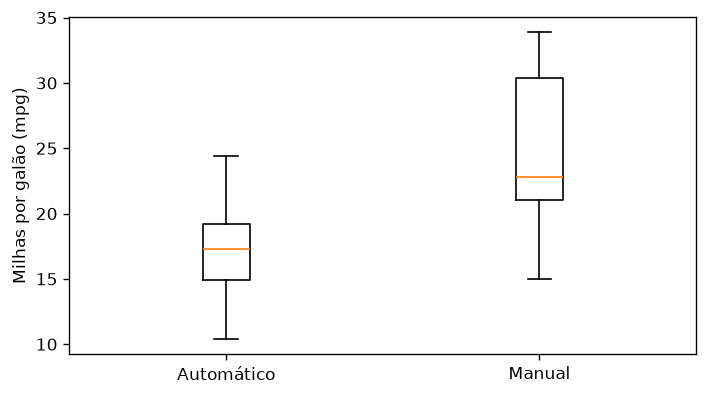

In [ ]:
manual = mtcars.loc[mtcars["am"].eq(1), "mpg"].to_numpy()
automatico = mtcars.loc[mtcars["am"].eq(0), "mpg"].to_numpy()

resumo_carros = mtcars.assign(cambio=mtcars["am"].map({1: "Manual", 0: "Automático"}))
display(resumo_carros.groupby("cambio")["mpg"].agg(["size", "mean", "median", "std"]).round(3))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.boxplot([automatico, manual])
ax.set(xticks=[1, 2], xticklabels=["Automático", "Manual"], ylabel="Milhas por galão (mpg)")
plt.tight_layout()
plt.show()

dias = np.arange(365)
dias_lua_cheia = np.rint(np.arange(12) * 29.53 + 14)
atendimentos = np.random.default_rng(2726).poisson(lam=120, size=len(dias))
lua_cheia = np.isin(dias, dias_lua_cheia)

## 3. Permutação e teste t

Para cada teste de permutação, sorteio 10.000 rearranjos com semente 2026. Comparo as diferenças em valor absoluto porque o teste é bilateral. A função também aceita a mediana. No teste de Welch, a diferença de médias é dividida pelo erro-padrão estimado a partir dos dois grupos.

,Diferença de médias,Permutações extremas,Fração extrema,t de Welch,p de Welch
Câmbio (mpg),7.244939,1.0,0.0001,3.767123,0.001374
Lua cheia (atendimentos),3.884797,2300.0,0.2300,1.404815,0.185340


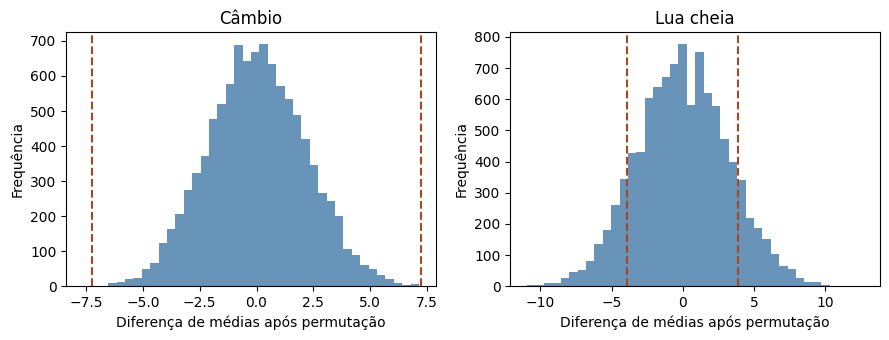

In [4]:
def diferenca(valores, grupo, medida=np.mean):
    return medida(valores[grupo]) - medida(valores[~grupo])

def permutation_null(valores, grupo, medida=np.mean, n_perm=10_000, seed=2026):
    rng = np.random.default_rng(seed)
    nula = np.empty(n_perm)
    for i in range(n_perm):
        rotulos = rng.permutation(grupo)
        nula[i] = diferenca(valores, rotulos, medida)
    return nula

def contar_extremos(nula, observado):
    valores = np.abs(nula)
    limite = abs(observado)
    return np.count_nonzero((valores > limite) | np.isclose(valores, limite, rtol=0, atol=1e-12))

def comparar_medias(valores, grupo):
    observado = diferenca(valores, grupo)
    nula = permutation_null(valores, grupo)
    extremos = contar_extremos(nula, observado)
    teste = stats.ttest_ind(valores[grupo], valores[~grupo], equal_var=False)
    resultado = {
        "Diferença de médias": observado,
        "Permutações extremas": extremos,
        "Fração extrema": extremos / len(nula),
        "t de Welch": teste.statistic,
        "p de Welch": teste.pvalue,
    }
    return resultado, nula

carros, nula_carros = comparar_medias(mtcars["mpg"].to_numpy(), mtcars["am"].eq(1).to_numpy())
dias = np.arange(365)
dias_lua_cheia = np.rint(np.arange(12) * 29.53 + 14)
atendimentos = np.random.default_rng(2726).poisson(lam=120, size=len(dias))
lua_cheia = np.isin(dias, dias_lua_cheia)
lua, nula_lua = comparar_medias(atendimentos, lua_cheia)
display(pd.DataFrame({"Câmbio (mpg)": carros, "Lua cheia (atendimentos)": lua}).T)

fig, eixos = plt.subplots(1, 2, figsize=(9, 3.5))
for eixo, nula, resultado, titulo in zip(
    eixos, (nula_carros, nula_lua), (carros, lua), ("Câmbio", "Lua cheia"),
):
    eixo.hist(nula, bins=40, color="#6994ba")
    limite = abs(resultado["Diferença de médias"])
    for ponto in (-limite, limite):
        eixo.axvline(ponto, color="#a64724", linestyle="--")
    eixo.set(title=titulo, xlabel="Diferença de médias após permutação", ylabel="Frequência")
plt.tight_layout()
plt.show()

A diferença de eficiência entre câmbios é bem rara na distribuição nula. Mas a diferença de atendimentos é comum no cenário em que os dias vem da mesma distribuição. O p-valor da lua cheia descreve a frequência de resultados extremos sob a hipótese nula. No caso dos carros, peso, potência e número de cilindros podem se relacionar com o câmbio e com o consumo, onde o teste aponta uma associação na amostra e a causa permanece em aberto.

## 4. Decisão em muitos testes e tamanho do efeito

Simulo 20 hospitais sem efeito da lua. Comparo o limiar usual de 0,05 com o de Bonferroni. A última tabela mantém o efeito fixo em 0,02 desvio-padrão e mostra como o p-valor diminui com o aumento da amostra. O tamanho do efeito e seu contexto continuam necessários para avaliar a importância prática.

In [5]:
rng = np.random.default_rng(7)
p_hospitais = stats.ttest_ind(
    rng.poisson(120, size=(20, 12)),
    rng.poisson(120, size=(20, 353)),
    axis=1, equal_var=False,
).pvalue

limiares = pd.Series({"Sem correção": 0.05, "Bonferroni": 0.05 / len(p_hospitais)})
display(limiares.rename("Limiar").to_frame().assign(
    rejeicoes=[int((p_hospitais <= corte).sum()) for corte in limiares],
))

n = np.array([100, 1_000, 10_000, 100_000, 1_000_000])
t = 0.02 * np.sqrt(n / 2)
display(pd.DataFrame({"n por grupo": n, "p-valor para d = 0,02": 2 * stats.t.sf(t, 2 * n - 2)}))

,Limiar,rejeicoes
Sem correção,0.0500,1
Bonferroni,0.0025,0


,n por grupo,"p-valor para d = 0,02"
0,100,8.876809e-01
1,1000,6.547693e-01
2,10000,1.573148e-01
3,100000,7.748470e-06
4,1000000,2.099060e-45


## Para casa

### 1. Permutação das medianas com o automático de 60 mpg

Acrescento o valor fictício ao grupo de automáticos. Comparo a diferença de medianas por permutação com a diferença de médias pelo teste t de Welch no mesmo cenário.

In [7]:
manual = mtcars.loc[mtcars["am"].eq(1), "mpg"].to_numpy()
automatico = mtcars.loc[mtcars["am"].eq(0), "mpg"].to_numpy()
automatico_60 = np.append(automatico, 60)
valores_60 = np.concatenate([manual, automatico_60])
rotulos_60 = np.arange(len(valores_60)) < len(manual)

delta_mediana = diferenca(valores_60, rotulos_60, np.median)
nula_mediana = permutation_null(valores_60, rotulos_60, medida=np.median)
extremos_mediana = contar_extremos(nula_mediana, delta_mediana)
p_mediana = extremos_mediana / len(nula_mediana)
welch_60 = stats.ttest_ind(manual, automatico_60, equal_var=False)
delta_media_60 = manual.mean() - automatico_60.mean()

display(pd.DataFrame({
    "Diferença (mpg)": [delta_mediana, delta_media_60],
    "p-valor": [p_mediana, welch_60.pvalue],
}, index=["Permutação das medianas", "Welch (médias)"]).round(5))

,Diferença (mpg),p-valor
Permutação das medianas,5.25000,0.02280
Welch (médias),5.10231,0.08484


**Resposta:** Com o automático de 60 mpg, a mediana dos manuais ficou 5,25 mpg acima da dos automáticos. A permutação das medianas deu p = 0,0228, com 228 de 10.000 diferenças pelo menos tão extremas quanto a observada. O teste t de Welch para as médias deu p = 0,08484.

A 5%, a permutação das medianas rejeita a hipótese nula. O teste de Welch deixa de rejeitá-la. O valor de 60 mpg eleva a média e a dispersão dos automáticos, o que reduz a estatística t. A mediana depende da ordem e é menos sensível ao valor. Os testes resumem a diferença entre os grupos por medidas distintas.

### 2. Aluguel de mobiliados e não mobiliados

Uso a ordem mobiliados menos não mobiliados. Repito os dois testes sobre os valores originais e sobre o logaritmo natural dos mesmos aluguéis. Na escala logarítmica, a diferença de médias está em unidades de log.

In [8]:
aluguel = imoveis["rent_amount"].to_numpy()
mobiliado = imoveis["furniture"].eq("furnished").to_numpy()
assert (aluguel > 0).all(), "O logaritmo exige aluguéis positivos."
assert set(imoveis["furniture"]) == {"furnished", "not furnished"}

display(imoveis.groupby("furniture")["rent_amount"].agg(["size", "mean", "median"]).round(2))
aluguel_reais, _ = comparar_medias(aluguel, mobiliado)
aluguel_log, _ = comparar_medias(np.log(aluguel), mobiliado)
display(pd.DataFrame({"Aluguel em reais": aluguel_reais, "Log do aluguel": aluguel_log}).T)

,size,mean,median
furniture,,,
furnished,10177,4398.87,3200.0
not furnished,19262,3849.03,2740.0


,Diferença de médias,Permutações extremas,Fração extrema,t de Welch,p de Welch
Aluguel em reais,549.832951,0.0,0.0,12.238460,2.603750e-34
Log do aluguel,0.150466,0.0,0.0,15.512553,5.666924e-54


**Resposta:** Os 10.177 imóveis mobiliados tinham aluguel médio de `R$ 4.398,87`. Nos 19.262 não mobiliados, a média foi de `R$ 3.849,03`.

| Escala | Diferença observada | Permutação bilateral | Teste t de Welch |
|---|---:|---:|---:|
| Aluguel em reais | R$ 549,83 | 0 de 10.000 permutações extremas | 2,60 × 10⁻³⁴ |
| Log do aluguel | 0,15047 | 0 de 10.000 permutações extremas | 5,67 × 10⁻⁵⁴ |

O zero na coluna de permutação é a contagem de resultados extremos. Seguindo o critério da aula, reporto p < 0,001 nas duas escalas. Nas duas, o aluguel foi maior entre os mobiliados e os testes rejeitaram a hipótese nula a 5%. O log comprime os aluguéis mais altos. A diferença de 0,15047 está na escala logarítmica, e a diferença de R$ 549,83 expressa o efeito observado em reais. Os testes mostram uma associação entre mobília e aluguel.

### 3. A área pode explicar parte da associação?

Eu acredito que a área pode ser um confundidor, pois ela pode se relacionar com a chance de um imóvel ser mobiliado e com seu aluguel. O primeiro painel compara as áreas dos dois grupos. No segundo, comparo as medianas de aluguel por mobília dentro das mesmas faixas de área, formadas pelos quartis da base.

,Área mediana (m²)
mobília,
Mobiliado,75.8
Não mobiliado,75.7


mobília,Não mobiliado,Mobiliado
faixa de área,,
"(19.999, 54.5]",1350.00,1610.00
"(54.5, 75.8]",2270.00,2648.69
"(75.8, 110.1]",3407.14,4120.00
"(110.1, 500.0]",6590.00,7106.65


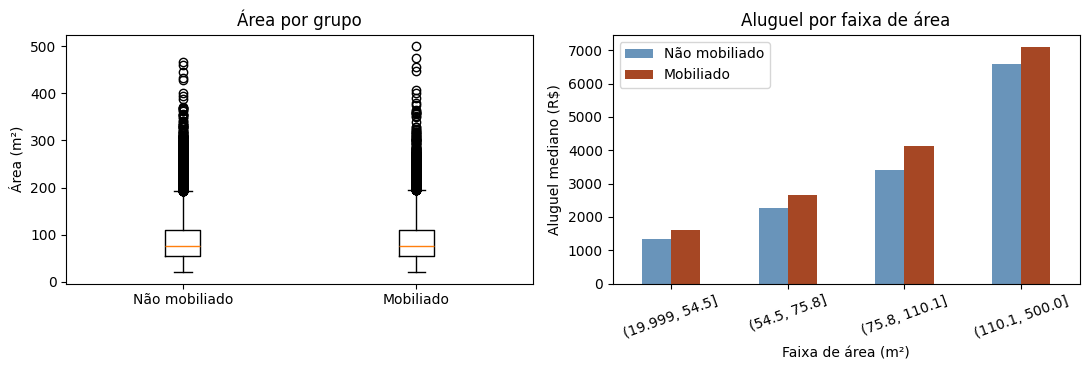

In [9]:
com_area = imoveis.dropna(subset=["area"]).copy()
com_area["mobília"] = com_area["furniture"].map({
    "furnished": "Mobiliado", "not furnished": "Não mobiliado",
})
com_area["faixa de área"] = pd.qcut(com_area["area"], q=4)
ordem = ["Não mobiliado", "Mobiliado"]
area_grupos = com_area.groupby("mobília")["area"]
medianas_area = area_grupos.median()
por_faixa = (
    com_area.groupby(["faixa de área", "mobília"], observed=True)["rent_amount"]
    .median().unstack()[ordem]
)
display(medianas_area.rename("Área mediana (m²)").to_frame())
display(por_faixa.round(2))

fig, (esq, dir_) = plt.subplots(1, 2, figsize=(11, 3.8))
esq.boxplot([area_grupos.get_group(grupo) for grupo in ordem])
esq.set(xticks=[1, 2], xticklabels=ordem, ylabel="Área (m²)", title="Área por grupo")
por_faixa.plot.bar(ax=dir_, color=["#6994ba", "#a64724"], rot=20)
dir_.set(xlabel="Faixa de área (m²)", ylabel="Aluguel mediano (R$)", title="Aluguel por faixa de área")
dir_.legend(title=None)
plt.tight_layout()
plt.show()

**Resposta:** Usei área como possível confundidor. O aluguel mediano aumenta nas faixas de maior área, mas as áreas medianas dos dois grupos são próximas, com 75,8 m² nos mobiliados e 75,7 m² nos não mobiliados. Em todas as quatro faixas de área, o aluguel mediano dos mobiliados continuou maior. Na faixa de 75,8 a 110,1 m² as medianas foram `R$ 4.120,00` e `R$ 3.407,14`, por exemplo.

O gráfico sugere que a área sozinha explica pouco da associação observada. As faixas ainda reúnem imóveis de tamanhos diferentes, e outras características também podem influenciar o aluguel. Para atribuir um efeito a mobília, seria necessário comparar imóveis semelhantes nas outras características relevantes.